# Demostración: delegación del Supervisor entre agentes especialistas

Este notebook corre el orquestador **de verdad** (modelo Claude real, herramientas reales sobre los datos ficticios de *Mercado Austral*) y deja a la vista cómo el Supervisor delega.

Qué se puede ver acá:

1. El **grafo** (generado por LangGraph a partir de los nodos y aristas reales).
2. **Tres tareas** distintas: dos que requieren a los tres especialistas y una **fuera de alcance**, donde el Supervisor tiene que saltear al Analista.
3. Para cada tarea, la **traza paso a paso**: a quién delegó el Supervisor, con qué instrucción, qué herramientas usó cada agente, y qué dijo la validación.

> Las celdas son finas a propósito: la lógica vive en `ejecucion.py`, `supervisor.py` y `validacion.py`, que están cubiertos por tests. Para correrlo hace falta `ANTHROPIC_API_KEY` en el archivo `.env` (nunca en el notebook).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # el notebook vive en notebooks/, el código en la raíz

from IPython.display import Image, Markdown, display

from config import Configuracion
from ejecucion import crear_grafo, ejecutar_tarea
from main import ESCENARIOS
from trazas import a_log

config = Configuracion.desde_entorno()
grafo = crear_grafo(config)
print(f"Modelo del supervisor: {config.modelo_supervisor} | modelo de los especialistas: {config.modelo_especialistas}")
print(f"Límites: máx. {config.max_pasos} delegaciones por tarea, máx. {config.max_intentos_por_agente} intentos por agente")

Modelo del supervisor: claude-haiku-4-5 | modelo de los especialistas: claude-haiku-4-5
Límites: máx. 10 delegaciones por tarea, máx. 3 intentos por agente


## 1. El grafo

Lo que se ve abajo es `docs/grafo.png`, generado desde `grafo.get_graph().draw_mermaid()`. Las líneas punteadas son las **aristas condicionales**: solo el Supervisor decide a dónde va el control.

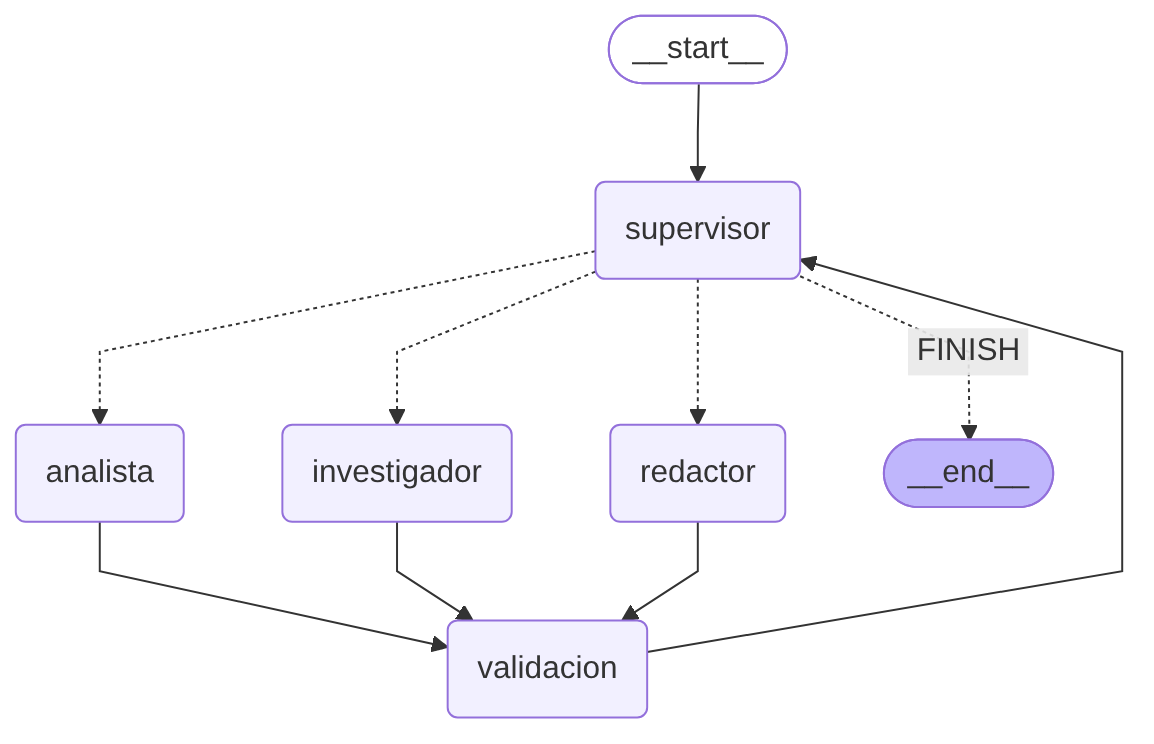

In [2]:
display(Image(filename=str(Path.cwd().parent / "docs" / "grafo.png")))

## 2. Tarea 1: priorización multi-agente (maestro de artículos)

El Supervisor tiene que armar la cadena **Investigador → Analista → Redactor** por su cuenta.

In [3]:
corridas = []
escenario, tarea = ESCENARIOS[0]
corridas.append(await ejecutar_tarea(grafo, tarea, config, escenario))
print(a_log(corridas[-1:]))

=== 1. Priorización multi-agente (maestro de artículos) ===
Tarea: "Necesito saber qué incidentes críticos abiertos tiene el maestro de artículos, qué regla incumple cada uno, cuánto se pasaron del plazo (SLA) y cuál conviene atacar primero. Armame un informe corto."

[Paso 1] Supervisor → investigador
           Motivo: Iniciamos el flujo recolectando los incidentes críticos del maestro de artículos y sus reglas asociadas, que son insumo obligatorio para el análisis.
           Instrucción: "Consulta los incidentes críticos abiertos del maestro de artículos e indica qué regla de calidad de datos incumple cada uno, su severidad y estado."
           Investigador usó: buscar_incidentes_calidad, detalle_incidente x2, consultar_regla_calidad x2
           Resumen: ## Resumen de Incidentes Críticos Abiertos - Maestro Artículos Se encontraron **2 incidentes críticos abiertos**: | ID | Título | Regla Incumplida | Descripción de la Regla | Severidad | Estado | |---|---|---|---|---|---| | **IN

## 3. Tarea 2: otro maestro, con más incidentes (proveedores)

In [4]:
escenario, tarea = ESCENARIOS[1]
corridas.append(await ejecutar_tarea(grafo, tarea, config, escenario))
print(a_log(corridas[-1:]))

=== 2. Otro maestro con más incidentes (proveedores) ===
Tarea: "Priorizá todos los incidentes abiertos del maestro de proveedores: qué reglas incumplen, cómo está el vencimiento del SLA de cada uno y en qué orden hay que atenderlos. Quiero un informe corto."

[Paso 1] Supervisor → investigador
           Motivo: Arrancamos por el investigador. Necesitamos mapear los incidentes abiertos y sus reglas incumplidas antes de calcular prioridades.
           Instrucción: "Consulta todos los incidentes abiertos del maestro de proveedores. Reporta para cada uno: ID, reglas de calidad de datos incumplidas, severidad y fecha de apertura."
           Investigador usó: buscar_incidentes_calidad, detalle_incidente x3, consultar_regla_calidad x3
           Resumen: ## Reporte: Incidentes Abiertos del Maestro de Proveedores | ID | Regla de Calidad Incumplida | Severidad | Fecha de Apertura | |---|---|---|---| | **INC-2001** | R-PRV-01: CUIT valido (El CUIT del proveedor activo debe tener 11 dígitos y

## 4. Tarea 3: consulta fuera de alcance

No hay datos de empleados ni de sueldos. Lo esperable: el Investigador lo declara, el Supervisor **no** manda a calcular nada y el Redactor responde sin inventar.

In [5]:
escenario, tarea = ESCENARIOS[2]
corridas.append(await ejecutar_tarea(grafo, tarea, config, escenario))
print(a_log(corridas[-1:]))

=== 3. Consulta fuera de alcance ===
Tarea: "¿Cuántos empleados tiene Mercado Austral y cuánto cobra el gerente de datos?"

[Paso 1] Supervisor → investigador
           Motivo: Inicio del proceso: el investigador es siempre el primero. Esta tarea no trata sobre incidentes ni reglas de calidad de datos, por lo que el investigador debe evaluar si está fuera de alcance.
           Instrucción: "Verifica si es posible consultar datos sobre cantidad de empleados y salario del gerente de datos de Mercado Austral. Si no está dentro del alcance de gestión de incidentes y reglas de calidad de datos, declara la consulta fuera de alcance."
           Investigador usó: ninguna
           Resumen: FUERA_DE_ALCANCE La consulta sobre cantidad de empleados y salario del gerente de datos no está relacionada con incidentes de calidad de datos ni con reglas de calidad. Mis herramientas solo permiten investigar incidentes de maestros de datos (artículos, proveedores, sucursales) y consultar reglas de cal

## 5. Resumen de las tres corridas

In [6]:
print(f"{'escenario':58} {'estado':12} {'agentes':34} {'deleg.':>6} {'guardas':>7} {'tokens':>8}")
for c in corridas:
    agentes = ", ".join(c.agentes_que_intervinieron)
    print(f"{c.escenario[:57]:58} {c.estado_final:12} {agentes:34} {c.pasos_del_supervisor:>6} "
          f"{c.decisiones_corregidas_por_guarda:>7} {c.tokens_entrada + c.tokens_salida:>8}")

escenario                                                  estado       agentes                            deleg. guardas   tokens
1. Priorización multi-agente (maestro de artículos)        completado   investigador, analista, redactor        3       0    32562
2. Otro maestro con más incidentes (proveedores)           completado   investigador, analista, redactor        3       0    35620
3. Consulta fuera de alcance                               completado   investigador, redactor                  2       0     8447
